# M3 — Introductory tool notebook
Basic examples of NetworkX, pandas, Matplotlib and scikit-learn.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'm34.py').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from m34 import normalize, encode, decode, pairs, build_records, pilot_graphs, FORMATS
%matplotlib inline
plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (5.4, 2.6), 'font.size': 9})

## NetworkX: normalize a directed graph and check exact answers

In [2]:
g = nx.DiGraph([(4,8),(8,4),(8,9),(9,9)])
g.add_node(12)
h = normalize(g)
print('Nodes:', list(h.nodes()), 'Edges:', pairs(h))
print('Edge 1 -> 2:', h.has_edge(1,2), '; reverse:', h.has_edge(2,1))
print('Isolates:', list(nx.isolates(h)))

Nodes: [0, 1, 2, 3] Edges: [(0, 1), (1, 0), (1, 2)]
Edge 1 -> 2: True ; reverse: False
Isolates: [3]


## pandas and Matplotlib: representation costs

 encoding  bytes  roundtrip
edge_list     47       True
adjacency     53       True
  natural    108       True
  compact    106       True


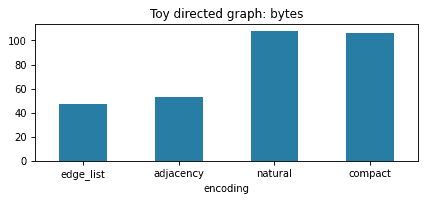

In [3]:
frame = pd.DataFrame([{'encoding': fmt, 'bytes': len(encode(h,fmt).encode()), 'roundtrip': pairs(decode(encode(h,fmt),fmt)) == pairs(h)} for fmt in FORMATS])
print(frame.to_string(index=False))
frame.plot.bar(x='encoding',y='bytes',legend=False,title='Toy directed graph: bytes', color='#287DA4', rot=0)
plt.tight_layout()
plt.show()

## scikit-learn: toy text classification API

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
model = make_pipeline(TfidfVectorizer(), LogisticRegression(random_state=2026))
model.fit(['direct link present','edge present','direct link absent','edge absent'], ['yes','yes','no','no'])
print(model.predict(['edge present','edge absent']))

['yes' 'no']


## Completed real-data run (19 November 2026)
The team ran Qwen2.5-0.5B-Instruct on real Facebook and Email-Eu-core data using `m34.py --mode llm --snap --limit 24` on an RTX 3050. Both dataset counts passed validation and all 96 predictions were saved. The notebook reads the actual saved CSVs; it does not rerun model inference.

## Transformers / Qwen: API usage and saved real result

In [5]:
# The experiment uses AutoTokenizer/AutoModelForCausalLM.from_pretrained,
# apply_chat_template, and model.generate(do_sample=False, max_new_tokens=8).
# Run m34.py --mode llm --snap --limit 24 to execute the actual model.
pred = pd.read_csv(ROOT / 'results/m34/llm_predictions.csv')
print('Model:', pred.model.unique().tolist(), '| Device:', pred.device.unique().tolist())
print(pred[['encoding','truth','prediction','prompt_tokens']].head(4).to_string(index=False))

Model: ['Qwen/Qwen2.5-0.5B-Instruct'] | Device: ['cuda']
 encoding truth prediction  prompt_tokens
edge_list    no        yes            371
adjacency    no        yes            397
  natural    no        yes            559
  compact    no        yes            267
